In [117]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import MultipleLocator
from laboratory_data_analysis.pdf_functions import ReportPDF, add_text, add_chart_section

## Laboratory demand analysis

### Objective

Analyze historical laboratory demand to understand how workload changes over time, how patients use laboratory services, and whether there are patterns that can support operational planning.


In [118]:
def load_analysis_csv(filename, datetime_columns):
    """Load a cleaned CSV and restore its UTC datetime columns."""
    dataframe = pd.read_csv(f'../dataset/cleaned/{filename}')
    for column in datetime_columns:
        dataframe[column] = pd.to_datetime(dataframe[column], utc=True, errors='raise')
    return dataframe


item_analysis_df = load_analysis_csv(
    'item_analysis.csv', ['order_created_at']
)
report_analysis_df = load_analysis_csv(
    'report_analysis.csv', ['dispatched_at', 'order_created_at']
)
sample_state_analysis_df = load_analysis_csv(
    'sample_state_analysis.csv', ['timestamp', 'order_created_at']
).rename(columns={'timestamp': 'sample_state_datetime'})


def summarise_demand(dataframe, group_columns):
    """Return demand metrics at the requested analytical grain."""
    return (
        dataframe.groupby(group_columns, observed=True)
        .agg(
            orders=('order_id', 'nunique'),
            tests=('order_item_id', 'nunique'),
            patients=('patient_id', 'nunique'),
            revenue=('price', 'sum'),
        )
        .reset_index()
    )

In [119]:
def save_chart(filename, fig=None):
    if fig is None:
        fig = plt.gcf()

    fig.tight_layout()
    fig.savefig(
        f'../laboratory_demand_analysis_summary/{filename}.png',
        dpi=300,
        bbox_inches='tight'
    )
    plt.show()
    plt.close(fig)

## 1. Data preparation and validation

The three files have different analytical grains. The demand analyses below use `item_analysis_df`, where one row represents one ordered test (`order_item_id`).

In [120]:
data_inventory = pd.DataFrame(
    {
        'rows': [len(item_analysis_df), len(report_analysis_df), len(sample_state_analysis_df)],
        'unique_samples': [
            item_analysis_df['sample_id'].nunique(),
            report_analysis_df['sample_id'].nunique(),
            sample_state_analysis_df['sample_id'].nunique(),
        ],
    },
    index=['item_analysis_df', 'report_analysis_df', 'sample_state_analysis_df'],
)

## 2. Demand over time

This section answers: **When is laboratory demand highest?**

### Daily workload

In [121]:
demand_base = item_analysis_df.assign(
    date=item_analysis_df['order_created_at'].dt.normalize(),
    hour=item_analysis_df['order_created_at'].dt.hour,
    day_of_week=item_analysis_df['order_created_at'].dt.day_name(),
    month=item_analysis_df['order_created_at'].dt.tz_localize(None).dt.to_period('M'),
)

### Recurring weekly pattern

**Which days generally have higher laboratory workload?**

In [122]:
day_order = [
    'Monday',
    'Tuesday',
    'Wednesday',
    'Thursday',
    'Friday',
    'Saturday',
    'Sunday'
]

day_demand = (
    summarise_demand(demand_base, 'day_of_week')
      .set_index('day_of_week')
      .reindex(day_order)
      .rename_axis('day_of_week')
      .reset_index()
)

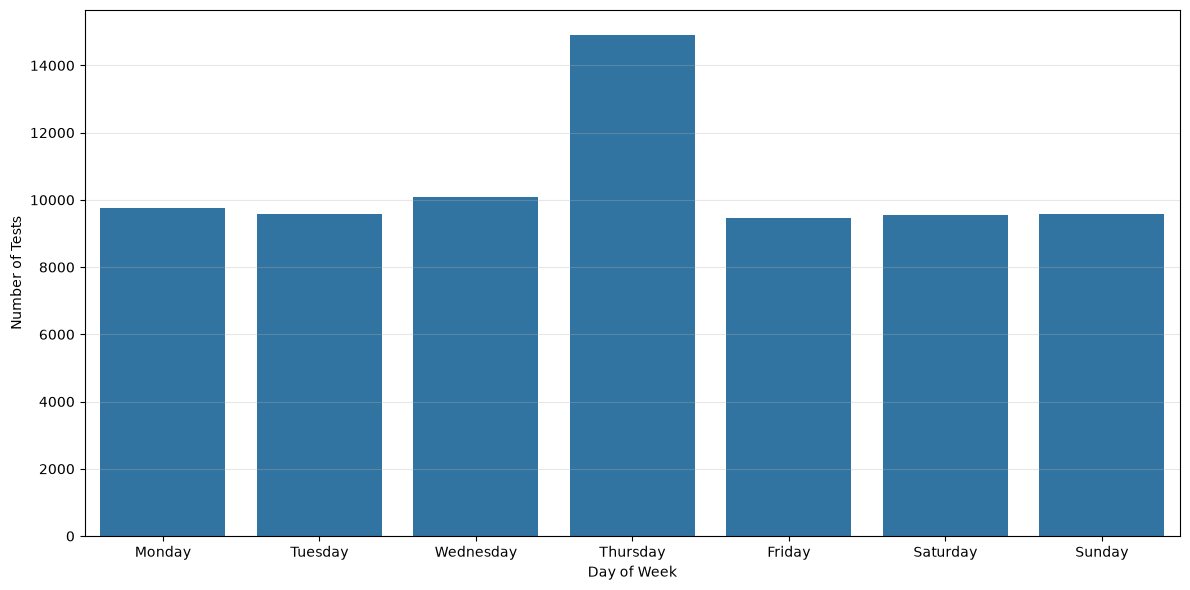

In [123]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=day_demand,
    x='day_of_week',
    y='tests'
)

plt.xlabel('Day of Week')
plt.ylabel('Number of Tests')

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
save_chart('lab_test_volume_by_day')

### Hourly demand

**At what time of day is laboratory workload generally highest?**

In [124]:
hourly_demand = (
    summarise_demand(demand_base, 'hour')
    .set_index('hour').reindex(range(24), fill_value=0).rename_axis('hour').reset_index()
)

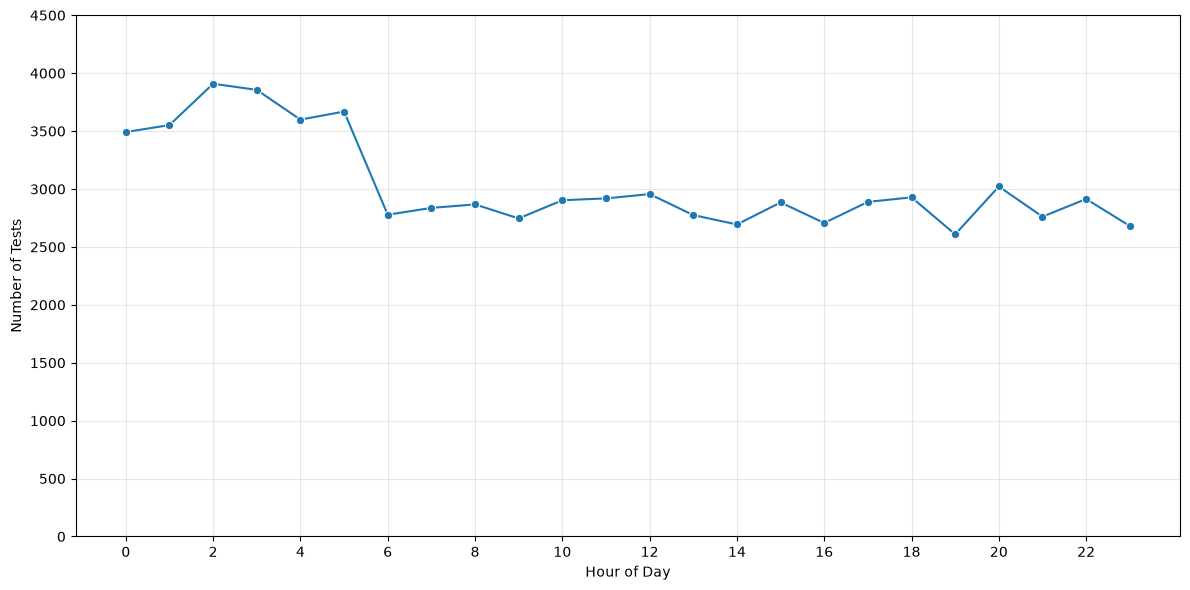

In [125]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=hourly_demand,
    x='hour',
    y='tests',
    marker='o'
)


plt.xlabel('Hour of Day')
plt.ylabel('Number of Tests')

plt.xticks(range(0, 24, 2))
plt.yticks(range(0, 5000, 500))
plt.grid(alpha=0.3)

plt.tight_layout()
save_chart('hourly_lab_test_volume')

### Day-and-hour workload profile

In [126]:
day_hour_demand = summarise_demand(demand_base, ['day_of_week', 'hour'])

In [127]:
heatmap_data = (
    day_hour_demand
    .pivot(
        index='day_of_week',
        columns='hour',
        values='tests'
    )
    .reindex(index=day_order, columns=range(24), fill_value=0)
)

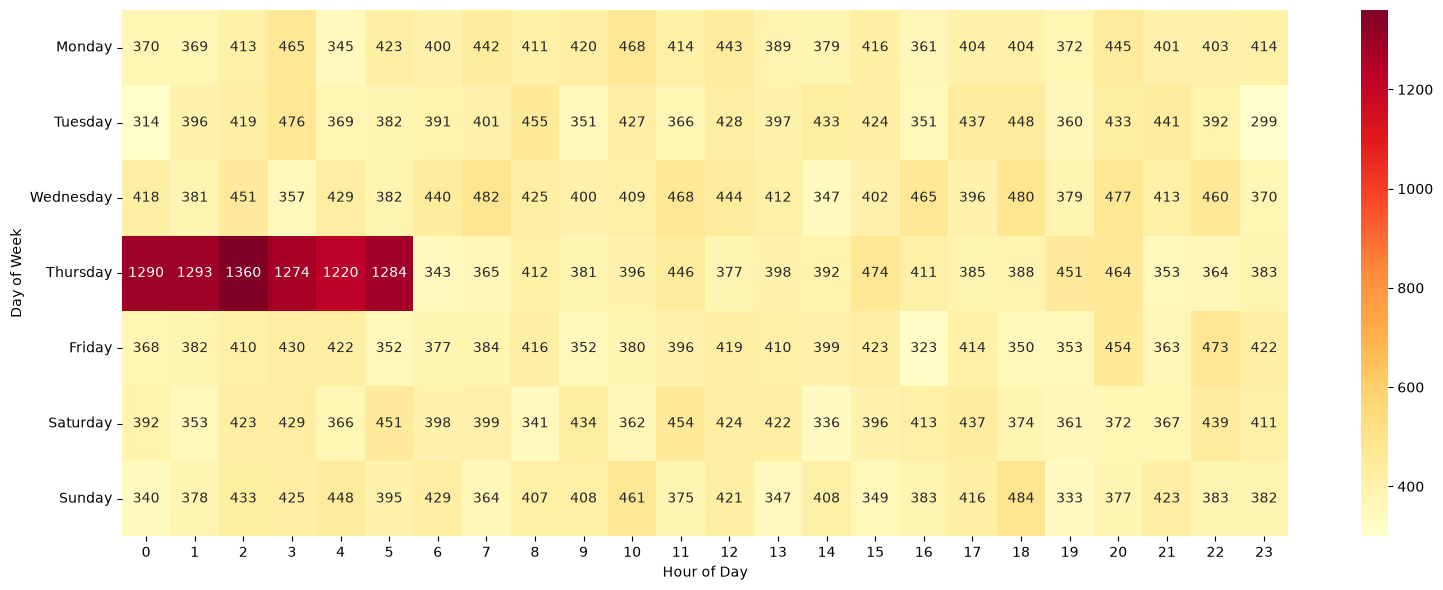

In [128]:
plt.figure(figsize=(16, 6))

sns.heatmap(
    heatmap_data,
    cmap='YlOrRd',
    annot=True,
    fmt='.0f'
)

plt.xlabel('Hour of Day')
plt.ylabel('Day of Week')

plt.tight_layout()
save_chart('workload_by_day_hour')

### Monthly workload

In [129]:
monthly_demand = summarise_demand(demand_base, 'month')

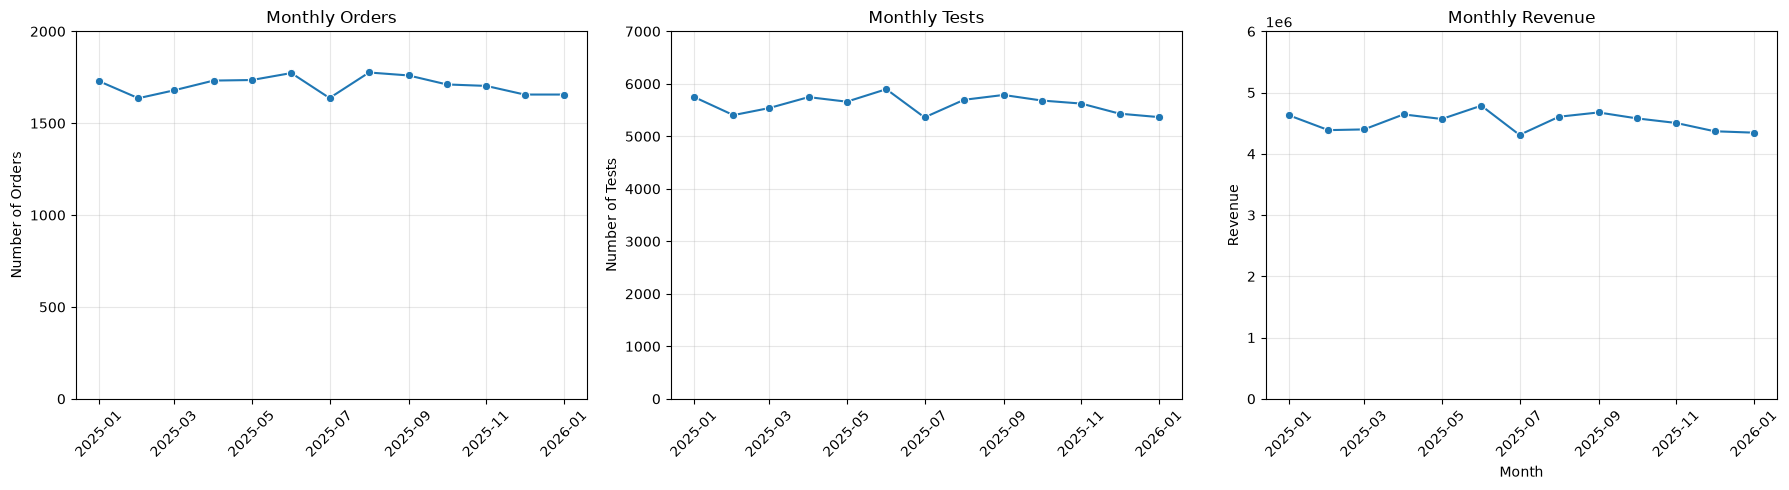

In [130]:
monthly_demand['month'] = monthly_demand['month'].dt.to_timestamp()

# Create 2x2 figure
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Orders
sns.lineplot(
    data=monthly_demand,
    x='month',
    y='orders',
    marker='o',
    ax=axes[0]
)
axes[0].set_title('Monthly Orders')
axes[0].set_xlabel('')
axes[0].set_ylabel('Number of Orders')
axes[0].set_ylim(0, 2000)
axes[0].yaxis.set_major_locator(MultipleLocator(500))

# 2. Tests
sns.lineplot(
    data=monthly_demand,
    x='month',
    y='tests',
    marker='o',
    ax=axes[1]
)
axes[1].set_title('Monthly Tests')
axes[1].set_xlabel('')
axes[1].set_ylabel('Number of Tests')
axes[1].set_ylim(0, 7000)
axes[1].yaxis.set_major_locator(MultipleLocator(1000))


# 4. Revenue
sns.lineplot(
    data=monthly_demand,
    x='month',
    y='revenue',
    marker='o',
    ax=axes[2]
)
axes[2].set_title('Monthly Revenue')
axes[2].set_xlabel('Month')
axes[2].set_ylabel('Revenue')
axes[2].set_ylim(0, 6000000)
axes[2].yaxis.set_major_locator(MultipleLocator(1000000))

# Overall formatting
for ax in axes.flat:
    ax.tick_params(axis='x', rotation=45)
    ax.grid(True, alpha=0.3)


plt.tight_layout()

save_chart('monthly_laboratory_demand_trends', fig)

## 3. Demand by department

**Which departments generate the most workload?**

In [131]:
department_demand = (
    summarise_demand(item_analysis_df, 'department_name')
      .sort_values('tests', ascending=False)
)

### Department comparison

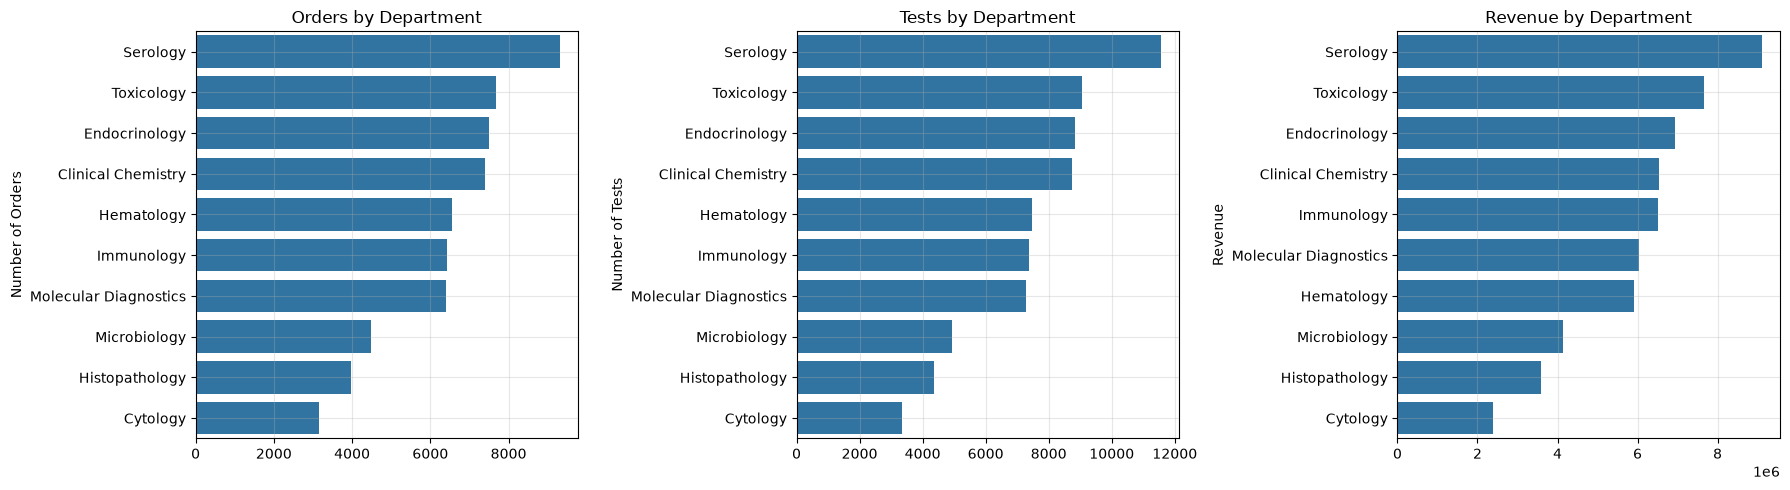

In [132]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Orders
sns.barplot(
    data=department_demand.sort_values('orders', ascending=False),
    x='orders',
    y='department_name',
    ax=axes[0]
)
axes[0].set_title('Orders by Department')
axes[0].set_xlabel('')
axes[0].set_ylabel('Number of Orders')

# 2. Tests
sns.barplot(
    data=department_demand,
    x='tests',
    y='department_name',
    ax=axes[1]
)
axes[1].set_title('Tests by Department')
axes[1].set_xlabel('')
axes[1].set_ylabel('Number of Tests')

# 4. Revenue
sns.barplot(
    data=department_demand.sort_values('revenue', ascending=False),
    x='revenue',
    y='department_name',
    ax=axes[2]
)
axes[2].set_title('Revenue by Department')
axes[2].set_xlabel('')
axes[2].set_ylabel('Revenue')


for ax in axes.flat:
    ax.tick_params(axis='x')
    ax.grid(True, alpha=0.3)

plt.tight_layout()
save_chart('department_demand_trends', fig)

## Test Demand Analysis

**How does test demand change over time?**

In [133]:
test_demand_order = (
    summarise_demand(
        demand_base,
        ['test_name']
    )
    [['test_name', 'orders', 'revenue']]
    .sort_values('orders', ascending=False)
)

In [134]:
test_demand_revenue = (
    summarise_demand(
        demand_base,
        ['test_name']
    )
    [['test_name', 'orders', 'revenue']]
    .sort_values('revenue', ascending=False)
)

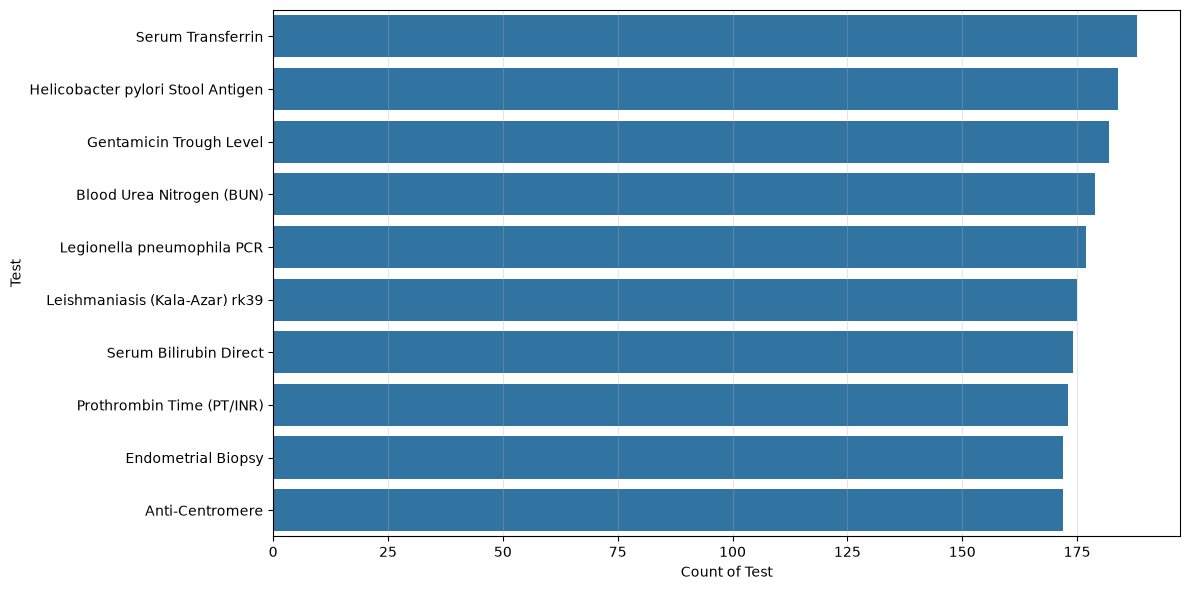

In [135]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=test_demand_order.head(10),
    x='orders',
    y='test_name'
)

plt.xlabel('Count of Test')
plt.ylabel('Test')

plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
save_chart('top_10_frequently_performed_tests')

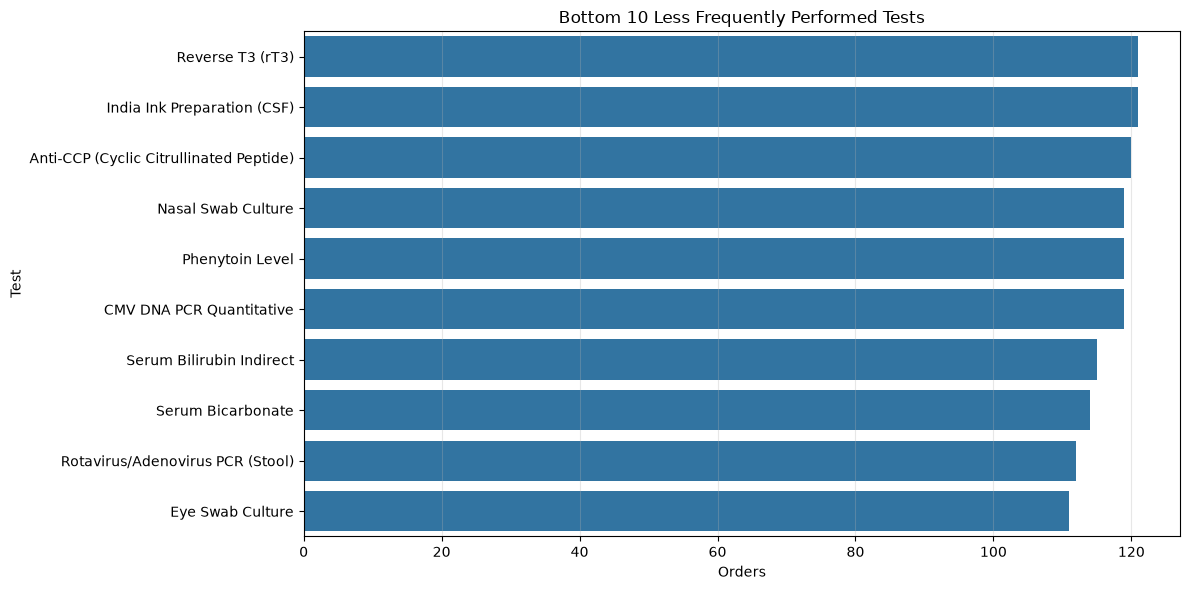

In [136]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=test_demand_order.tail(10),
    x='orders',
    y='test_name'
)

plt.title('Bottom 10 Less Frequently Performed Tests')
plt.xlabel('Orders')
plt.ylabel('Test')

plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
save_chart('less_frequent_performed_tests')

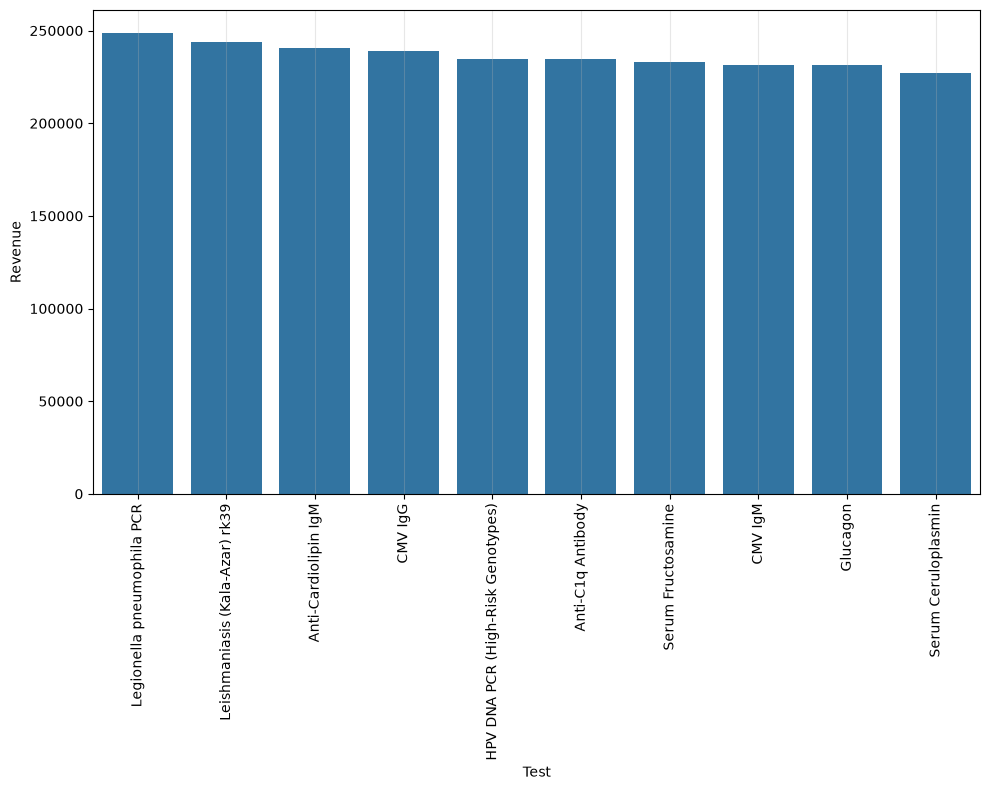

In [137]:
plt.figure(figsize=(10, 8))

sns.barplot(
    data=test_demand_revenue.head(10),
    x='test_name',
    y='revenue'
)

plt.xlabel('Test')
plt.ylabel('Revenue')
plt.xticks(rotation=90, ha='center') 
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
save_chart('top_10_tests_by_revenue')

In [138]:
pdf = ReportPDF()

pdf.add_page()

add_text(
    pdf,
    "Lab Test Volume by Day",
    bold=True,
    spacing_after=5
)

add_text(
    pdf,
    "This following chart shows the distribution of laboratory tests across weekdays to identify variations in daily workload and determine whether certain days experience higher testing demand.",
    bold=False,
    spacing_after=5
)

add_chart_section(
    pdf,
    "../laboratory_demand_analysis_summary/lab_test_volume_by_day.png"
)

add_text(
    pdf,
    "Key insights",
    bold=True,
    spacing_after=5
)

add_text(
    pdf,
    '''
    - Thursday has the highest workload, with 14,000+ tests, considerably higher than the other weekdays.
    - Test volume on the remaining weekdays remains relatively consistent at around 9,000 tests per day.
    - The Thursday peak represents roughly 5,000+ additional tests compared with the typical daily workload, making it the main day requiring attention.
    ''',
    bold=False,
    spacing_after=5
)

add_text(
    pdf,
    "Potential bottleneck",
    bold=True,
    spacing_after=5
)

add_text(
    pdf,
    "The concentration of additional workload on Thursday could put greater pressure on laboratory staff, analyzers, sample processing, and turnaround times if capacity is not adjusted accordingly.",
    bold=False,
    spacing_after=5
)

add_text(
    pdf,
    "Suggested action",
    bold=True,
    spacing_after=5
)

add_text(
    pdf,
    "Review staffing, analyzer utilization, and sample-processing capacity on Thursdays. If the higher demand is recurring, consider allocating additional resources or redistributing workload where operationally feasible.",
    bold=False,
    spacing_after=5
)

In [139]:
pdf.add_page()

add_text(
    pdf,
    "Hourly Laboratory Test Volume",
    bold=True,
    spacing_after=5
)

add_text(
    pdf,
    "This chart shows the distribution of laboratory tests across different hours in UTC of the day to identify peak testing periods and understand when workload is concentrated.",
    bold=False,
    spacing_after=5
)

add_chart_section(
    pdf,
    "../laboratory_demand_analysis_summary/hourly_lab_test_volume.png"
)

add_text(
    pdf,
    "Key insights",
    bold=True,
    spacing_after=5
)

add_text(
    pdf,
    '''
    - Test volume remains relatively high between 00:00 and 5:00 UTC, indicating the busiest period of laboratory activity.
    - After 5:00, test volume declines, suggesting reduced workload throughtout the day.
    - The concentration of testing from midnight through the early morning indicates that this is the primary period of operational demand.
    ''',
    bold=False,
    spacing_after=5
)

add_text(
    pdf,
    "Potential bottleneck",
    bold=True,
    spacing_after=5
)

add_text(
    pdf,
    "The sustained high workload between 00:00 and 5:00 UTC could create pressure on staff, analyzers, and sample-processing capacity, particularly if resources are not aligned with this demand.",
    bold=False,
    spacing_after=5
)

add_text(
    pdf,
    "Suggested action",
    bold=True,
    spacing_after=5
)

add_text(
    pdf,
    "Consider aligning staffing schedules, analyzer availability, and sample-processing resources with the 00:00 and 5:00 UTC peak to maintain smooth workflow and minimize the risk of delays.",
    bold=False,
    spacing_after=5
)

In [140]:
pdf.add_page()

add_text(
    pdf,
    "Workload by Day and Hour",
    bold=True,
    spacing_after=5
)

add_text(
    pdf,
    "This heatmap combines day-of-week and hourly test volumes to identify when laboratory workload is most concentrated and whether specific days experience stronger peak periods.",
    bold=False,
    spacing_after=5
)

add_chart_section(
    pdf,
    "../laboratory_demand_analysis_summary/workload_by_day_hour.png"
)

add_text(
    pdf,
    "Key insights",
    bold=True,
    spacing_after=5
)

add_text(
    pdf,
    '''
    - The highest workload is concentrated on Thursday between 00:00 and 5:00 UTC, where the heatmap shows the darkest intensity.
    - The overlap of these two peaks indicates that Thursday from midnight to early morning is the most demanding operational window.
    ''',
    bold=False,
    spacing_after=5
)

add_text(
    pdf,
    "Potential bottleneck",
    bold=True,
    spacing_after=5
)

add_text(
    pdf,
    "The combination of high daily volume and peak operational demand on Thursday may place additional pressure on staff, analyzers, and sample-processing capacity during this specific window.",
    bold=False,
    spacing_after=5
)

add_text(
    pdf,
    "Suggested action",
    bold=True,
    spacing_after=5
)

add_text(
    pdf,
    "Prioritize staffing, analyzer availability, and workflow capacity on Thursday afternoons, particularly between 00:00 and 5:00, and monitor TAT during this period to determine whether the increased workload is translating into delays.",
    bold=False,
    spacing_after=5
)

In [141]:
pdf.add_page()

add_text(
    pdf,
    "Monthly Laboratory Demand Trend",
    bold=True,
    spacing_after=5
)

add_text(
    pdf,
    "This line chart compares monthly orders, tests, and revenue to understand overall laboratory activity, identify periods of changing demand, and determine whether operational and financial metrics move together.",
    bold=False,
    spacing_after=5
)

add_chart_section(
    pdf,
    "../laboratory_demand_analysis_summary/monthly_laboratory_demand_trends.png"
)

add_text(
    pdf,
    "Key insights",
    bold=True,
    spacing_after=5
)

add_text(
    pdf,
    '''
    - Orders, tests, and revenue generally follow the same monthly pattern, indicating that changes in patient volume are accompanied by changes in laboratory activity and revenue.
    - July 2025 shows the only notable decline across all four metrics, suggesting a temporary reduction in overall laboratory activity.
    ''',
    bold=False,
    spacing_after=5
)

In [142]:
pdf.add_page()

add_text(
    pdf,
    "Department demand trend",
    bold=True,
    spacing_after=5
)

add_text(
    pdf,
    "This chart compares tests, orders, and revenue across laboratory departments to identify where workload is concentrated and which departments contribute most to overall laboratory activity and revenue.",
    bold=False,
    spacing_after=5
)

add_chart_section(
    pdf,
    "../laboratory_demand_analysis_summary/department_demand_trends.png"
)

add_text(
    pdf,
    "Key insights",
    bold=True,
    spacing_after=5
)

add_text(
    pdf,
    '''
    - Serology has the highest workload, recording the largest number of tests and orders among the departments.
    - The department also generates the highest revenue, showing that its high testing volume translates into a substantial financial contribution.
    - The alignment between tests, orders, and revenue suggests that departments handling greater testing demand are also contributing more to overall revenue.
    ''',
    bold=False,
    spacing_after=5
)

add_text(
    pdf,
    "Potential bottleneck",
    bold=True,
    spacing_after=5
)

add_text(
    pdf,
    "The concentration of workload in Serology may create a potential capacity pressure if staffing, analyzers, or other resources are not aligned with its higher testing demand.",
    bold=False,
    spacing_after=5
)

add_text(
    pdf,
    "Suggested action",
    bold=True,
    spacing_after=5
)

add_text(
    pdf,
    "Review Serology's staffing, analyzer utilization, and processing capacity against its workload. Maintaining sufficient capacity in this department can help manage demand while protecting turnaround times and revenue contribution.",
    bold=False,
    spacing_after=5
)

In [143]:
pdf.add_page()

add_text(
    pdf,
    "Top 10 most frequently performed tests",
    bold=True,
    spacing_after=5
)

add_text(
    pdf,
    "This chart ranks the 10 most frequently performed laboratory tests by test volume to identify which tests contribute most to overall testing demand.",
    bold=False,
    spacing_after=5
)


add_chart_section(
    pdf,
    "../laboratory_demand_analysis_summary/top_10_frequently_performed_tests.png"
)

add_text(
    pdf,
    "Key insights",
    bold=True,
    spacing_after=5
)

add_text(
    pdf,
    '''
    - Serum Transferrin is the most frequently performed test, indicating the highest testing demand among the top 10 tests.
    - The remaining tests show varying levels of demand, with the chart highlighting a clear ranking of the most frequently requested tests.
    - The concentration of demand among these tests can help identify which tests require consistent reagent availability, analyzer capacity, and workflow planning.
    ''',
    bold=False,
    spacing_after=5
)

add_text(
    pdf,
    "Potential bottleneck",
    bold=True,
    spacing_after=5
)

add_text(
    pdf,
    "High demand for Serum Transferrin could create a potential capacity or supply bottleneck if reagent availability, analyzer capacity, or processing resources are not aligned with its testing volume.",
    bold=False,
    spacing_after=5
)

add_text(
    pdf,
    "Suggested action",
    bold=True,
    spacing_after=5
)

add_text(
    pdf,
    "Monitor Serum Transferrin demand, reagent consumption, and analyzer utilization to ensure sufficient capacity and avoid interruptions in testing.",
    bold=False,
    spacing_after=5
)

In [144]:
pdf.add_page()

add_text(
    pdf,
    "Top 10 tests by revenue",
    bold=True,
    spacing_after=5
)

add_text(
    pdf,
    "This chart ranks the 10 laboratory tests generating the highest revenue to identify which tests contribute most to the laboratory's financial performance.",
    bold=False,
    spacing_after=5
)


add_chart_section(
    pdf,
    "../laboratory_demand_analysis_summary/top_10_tests_by_revenue.png"
)

add_text(
    pdf,
    "Key insights",
    bold=True,
    spacing_after=5
)

add_text(
    pdf,
    '''
    - Legionella pneumophilia PCR is the highest revenue-generating test, contributing approximately 250,000 in revenue.
    - Interestingly, the most frequently performed test, Serum Transferrin, does not generate the highest revenue, showing that testing volume and financial contribution do not necessarily follow the same pattern.
    - This indicates that test value/pricing can have a stronger impact on revenue than testing frequency alone.
    ''',
    bold=False,
    spacing_after=5
)

add_text(
    pdf,
    "Potential bottleneck",
    bold=True,
    spacing_after=5
)

add_text(
    pdf,
    "High-volume tests may consume substantial reagents, analyzer capacity, and staff time without being the largest contributors to revenue. Focusing only on test volume could therefore overlook financially important tests.",
    bold=False,
    spacing_after=5
)

add_text(
    pdf,
    "Suggested action",
    bold=True,
    spacing_after=5
)

add_text(
    pdf,
    "Evaluate tests using both volume and revenue contribution. High-revenue tests such as Legionella pneumophilia PCR should be monitored for reagent availability and processing capacity, while high-volume, lower-revenue tests should be assessed for their resource utilization and operational efficiency.",
    bold=False,
    spacing_after=5
)

In [145]:
pdf.output("../reports/laboratory_analysis.pdf")

''